In [ ]:
print("Customer Segmentation & Churn Pattern Analytics")
print("European Banking Project")
print("My Finance Analyst Internship Project")

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [9]:
df = pd.read_csv("European_Bank.csv")
df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [10]:
print("Dataset Shape:")
print(df.shape)
print("\ncolumn Names:")
print(df.columns.tolist())
print("nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(10000, 14)

column Names:
['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
nMissing Values:
Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [10]:
print("Duplicate rows:", df.duplicated().sum())

NameError: name 'df' is not defined

In [11]:
import pandas as pd

df = pd.read_csv("European_Bank.csv")

print("Data loaded successfully!")

Data loaded successfully!


In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [14]:
print("Customer churn count:")
print(df["Exited"].value_counts())

Customer churn count:
Exited
0    7963
1    2037
Name: count, dtype: int64


In [15]:
churn_percentage = df["Exited"].mean() * 100
print("Customer churn rate:", round(churn_percentage, 2), "%")

Customer churn rate: 20.37 %


In [16]:
churn_percentage = df["Exited"].mean() * 100

print("Customer churn rate:", round(churn_percentage, 2), "%")

Customer churn rate: 20.37 %


In [17]:
churn_by_country = df.groupby("Geography")["Exited"].mean() * 100

print(churn_by_country.round(2))

Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64


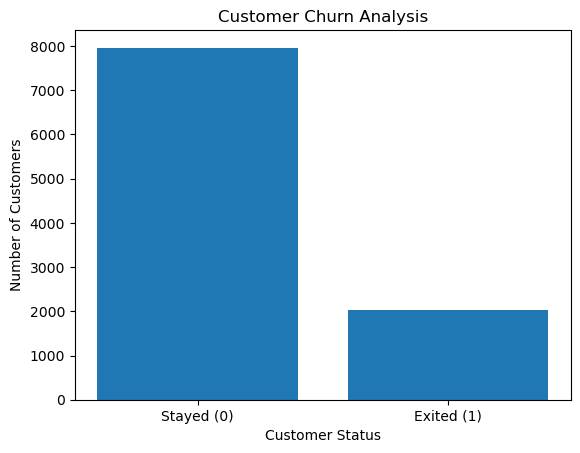

In [18]:
import matplotlib.pyplot as plt

churn_counts = df["Exited"].value_counts().sort_index()

plt.bar(
    ["Stayed (0)", "Exited (1)"],
    churn_counts.values
)

plt.title("Customer Churn Analysis")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.show()

In [19]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 30, 40, 50, float("inf")],
    labels=["18-30", "31-40", "41-50", "51+"]
)

print("Age groups created successfully!")

Age groups created successfully!


In [20]:
age_churn = df.groupby(
    "AgeGroup", observed=False
)["Exited"].mean() * 100

print("Churn rate by age group:")
print(age_churn.round(2))

Churn rate by age group:
AgeGroup
18-30     7.52
31-40    12.09
41-50    33.97
51+      44.65
Name: Exited, dtype: float64


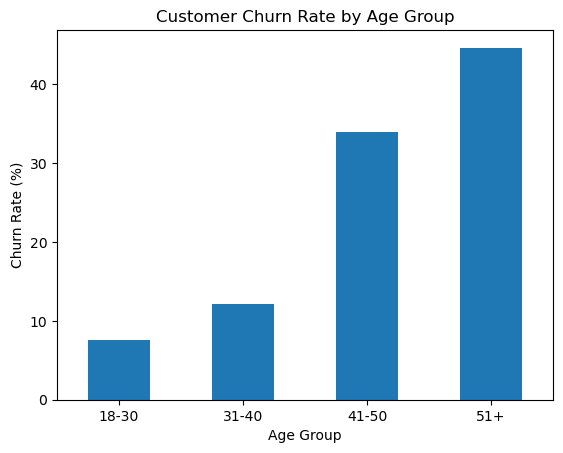

In [21]:
age_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [22]:
gender_churn = df.groupby("Gender")["Exited"].mean() * 100

print("Churn rate by gender:")
print(gender_churn.round(2))

Churn rate by gender:
Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64


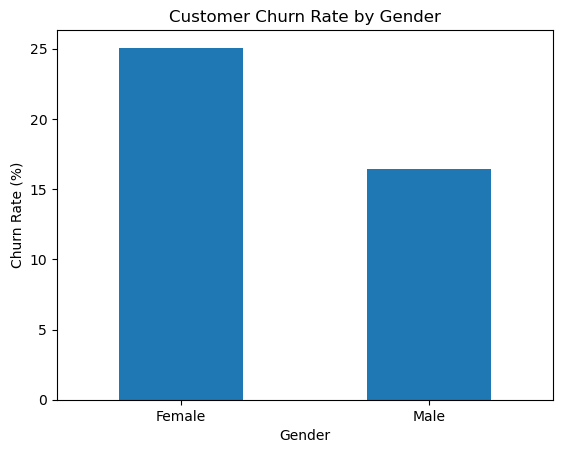

In [23]:
gender_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [24]:
df["CreditScoreGroup"] = pd.cut(
    df["CreditScore"],
    bins=[0, 580, 670, 740, 800, 900],
    labels=[
        "Low",
        "Fair",
        "Good",
        "Very Good",
        "Excellent"
    ],
    include_lowest=True
)

print("Credit score groups created!")

Credit score groups created!


In [25]:
credit_churn = (
    df.groupby("CreditScoreGroup", observed=False)["Exited"].mean() * 100
)

print("Churn rate by credit score:")
print(credit_churn.round(2))

Churn rate by credit score:
CreditScoreGroup
Low          22.15
Fair         20.39
Good         18.82
Very Good    20.25
Excellent    19.69
Name: Exited, dtype: float64


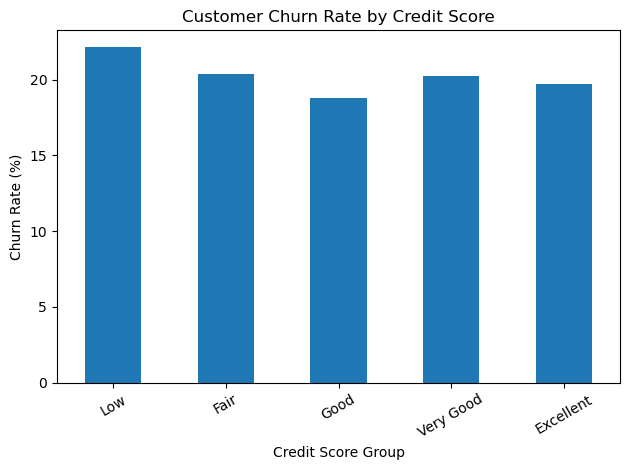

In [26]:
credit_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Credit Score")
plt.xlabel("Credit Score Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [27]:
df["BalanceGroup"] = pd.cut(
    df["Balance"],
    bins=[-1, 0, 50000, 100000, 150000, float("inf")],
    labels=[
        "Zero Balance",
        "1-50K",
        "50K-100K",
        "100K-150K",
        "150K+"
    ]
)

print("Balance groups created successfully!")

Balance groups created successfully!


In [28]:
balance_churn = (
    df.groupby("BalanceGroup", observed=False)["Exited"].mean() * 100
)

print("Churn rate by account balance:")
print(balance_churn.round(2))

Churn rate by account balance:
BalanceGroup
Zero Balance    13.82
1-50K           34.67
50K-100K        19.88
100K-150K       25.77
150K+           23.12
Name: Exited, dtype: float64


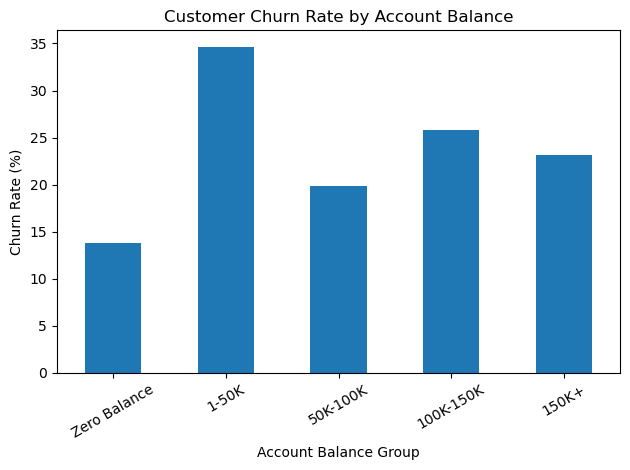

In [29]:
balance_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Account Balance")
plt.xlabel("Account Balance Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [30]:
df["TenureGroup"] = pd.cut(
    df["Tenure"],
    bins=[-1, 2, 5, 8, 10],
    labels=[
        "0-2 Years",
        "3-5 Years",
        "6-8 Years",
        "9-10 Years"
    ]
)

print("Tenure groups created successfully!")

Tenure groups created successfully!


In [31]:
tenure_churn = (
    df.groupby("TenureGroup", observed=False)["Exited"].mean() * 100
)

print("Churn rate by tenure:")
print(tenure_churn.round(2))

Churn rate by tenure:
TenureGroup
0-2 Years     21.15
3-5 Years     20.76
6-8 Years     18.87
9-10 Years    21.30
Name: Exited, dtype: float64


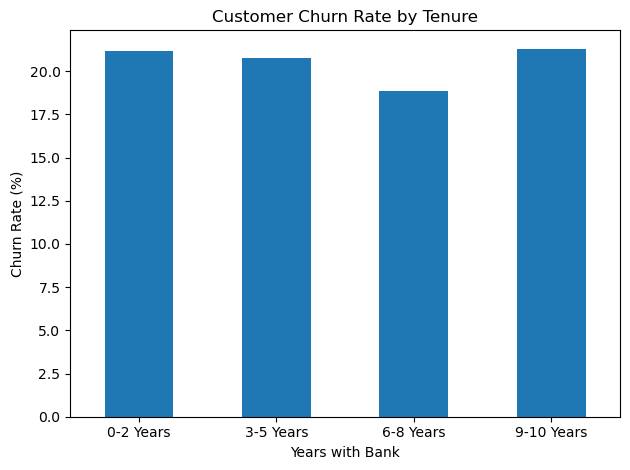

In [32]:
tenure_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Years with Bank")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
product_churn = (
    df.groupby("NumOfProducts")["Exited"].mean() * 100
)

print("Churn rate by number of products:")
print(product_churn.round(2))

Churn rate by number of products:
NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00
Name: Exited, dtype: float64


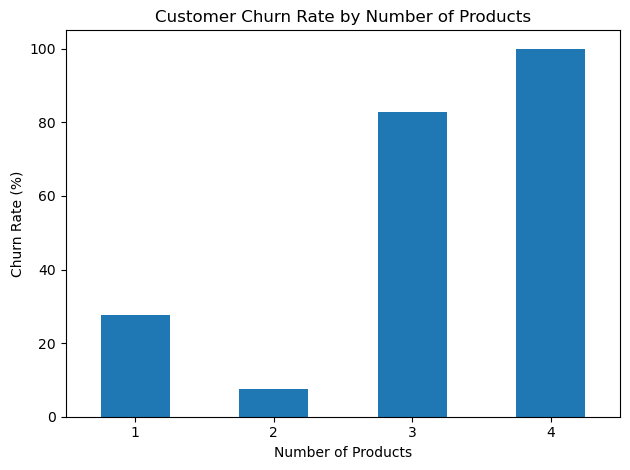

In [34]:
product_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [35]:
active_churn = df.groupby("IsActiveMember")["Exited"].mean() * 100

print("Churn rate by active status:")
print(active_churn.round(2))

Churn rate by active status:
IsActiveMember
0    26.85
1    14.27
Name: Exited, dtype: float64


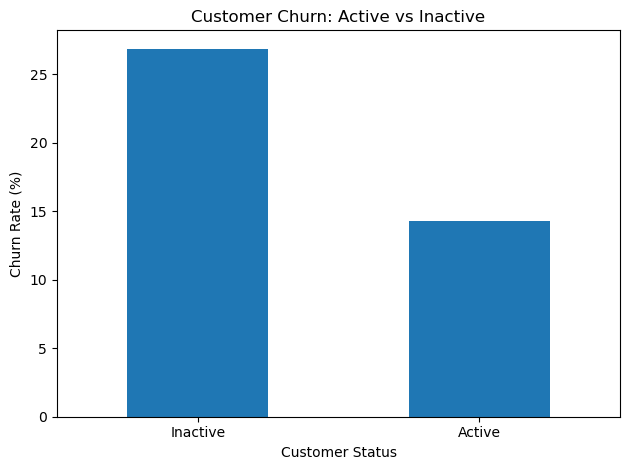

In [36]:
active_churn.index = ["Inactive", "Active"]

active_churn.plot(kind="bar")

plt.title("Customer Churn: Active vs Inactive")
plt.xlabel("Customer Status")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [37]:
total_customers = len(df)
churned_customers = (df["Exited"] == 1).sum()
retained_customers = (df["Exited"] == 0).sum()
churn_rate = df["Exited"].mean() * 100

print("Total Customers:", total_customers)
print("Customers Who Left:", churned_customers)
print("Customers Retained:", retained_customers)
print("Overall Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 10000
Customers Who Left: 2037
Customers Retained: 7963
Overall Churn Rate: 20.37 %


In [38]:
country_churn = df.groupby("Geography")["Exited"].mean() * 100
age_churn = df.groupby("AgeGroup", observed=False)["Exited"].mean() * 100
gender_churn = df.groupby("Gender")["Exited"].mean() * 100

print("Country with highest churn:", country_churn.idxmax())
print("Age group with highest churn:", age_churn.idxmax())
print("Gender with highest churn:", gender_churn.idxmax())

Country with highest churn: Germany
Age group with highest churn: 51+
Gender with highest churn: Female


In [39]:
findings = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Customers Who Left",
        "Customers Retained",
        "Overall Churn Rate (%)",
        "Highest Churn Country",
        "Highest Churn Age Group",
        "Highest Churn Gender"
    ],
    "Result": [
        total_customers,
        churned_customers,
        retained_customers,
        round(churn_rate, 2),
        country_churn.idxmax(),
        age_churn.idxmax(),
        gender_churn.idxmax()
    ]
})

findings

,Metric,Result
0,Total Customers,10000
1,Customers Who Left,2037
2,Customers Retained,7963
3,Overall Churn Rate (%),20.37
4,Highest Churn Country,Germany
5,Highest Churn Age Group,51+
6,Highest Churn Gender,Female


In [40]:
findings.to_csv("Customer_Churn_Findings.csv", index=False)

print("CSV file saved successfully!")

CSV file saved successfully!


In [41]:
findings.to_excel("Customer_Churn_Findings.xlsx", index=False)

print("Excel file saved successfully!")

Excel file saved successfully!


In [42]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Note: you may need to restart the kernel to use updated packages.


In [43]:
with pd.ExcelWriter("European_Bank_Analysis.xlsx") as writer:
    findings.to_excel(writer, sheet_name="Findings", index=False)
    country_churn.round(2).to_frame("Churn Rate (%)").to_excel(
        writer, sheet_name="Country Analysis"
    )
    age_churn.round(2).to_frame("Churn Rate (%)").to_excel(
        writer, sheet_name="Age Analysis"
    )
    gender_churn.round(2).to_frame("Churn Rate (%)").to_excel(
        writer, sheet_name="Gender Analysis"
    )
    balance_churn.round(2).to_frame("Churn Rate (%)").to_excel(
        writer, sheet_name="Balance Analysis"
    )
    tenure_churn.round(2).to_frame("Churn Rate (%)").to_excel(
        writer, sheet_name="Tenure Analysis"
    )
    product_churn.round(2).to_frame("Churn Rate (%)").to_excel(
        writer, sheet_name="Product Analysis"
    )
    active_churn.round(2).to_frame("Churn Rate (%)").to_excel(
        writer, sheet_name="Active Status"
    )

print("Complete analysis saved to Excel!")

Complete analysis saved to Excel!


# Customer Segmentation & Churn Pattern Analytics in European Banking

## 1. Introduction

Customer churn refers to customers who stop using a company's products or services. In the banking sector, customer churn can affect revenue, customer relationships, and long-term business growth.

This project analyzes customer data from a European bank to understand customer churn patterns. The analysis focuses on geography, age groups, gender, credit score, account balance, customer tenure, number of products, and active membership.

The main objective is to identify customer groups with higher churn rates and suggest strategies that may help the bank improve customer retention.

## 2. Objectives of the Project

- To analyze customer data and check data quality.
- To calculate the overall customer churn rate.
- To compare churn rates across different customer groups.
- To identify groups with relatively high churn rates.
- To suggest business strategies to improve customer retention.

## 3. Tools and Technologies

- Python
- Jupyter Notebook
- Pandas
- Matplotlib
- Excel
-

In [44]:
## 4. Dataset Description and Data Cleaning

The dataset contains information about bank customers, including their age, gender, geography, credit score, account balance, tenure, number of products, active membership, and churn status.

Before conducting the analysis, the dataset was checked for missing values, duplicate records, and data types.

The analysis found:
- Missing values: 0
- Duplicate records: 0

Therefore, no missing values or duplicate records were identified during the initial data quality checks.

The `Exited` column was used to identify churn status:
- 0 = Customer retained
- 1 = Customer exited
-

SyntaxError: invalid syntax (3662536822.py, line 3)

## 4. Dataset Description and Data Cleaning

The dataset contains information about bank customers, including their age, gender, geography, credit score, account balance, tenure, number of products, active membership, and churn status.

Before conducting the analysis, the dataset was checked for missing values, duplicate records, and data types.

The analysis found:
- Missing values: 0
- Duplicate records: 0

Therefore, no missing values or duplicate records were identified during the initial data quality checks.

The `Exited` column was used to identify churn status:
- 0 = Customer retained
- 1 = Customer exited
-

## 5. Key Findings

1. **Overall Churn:** The overall customer churn rate was approximately 20.37%.

2. **Geography:** Germany had the highest churn rate at approximately 32.44%, compared with France at 16.15% and Spain at 16.67%.

3. **Customer Segmentation:** Customers were grouped by age, gender, credit score, account balance, tenure, number of products, and active membership to compare churn patterns.

4. **Visual Analysis:** Bar charts were created to compare churn rates across different customer groups.

5. **Business Insight:** The bank should investigate why churn is higher in certain customer segments and develop targeted customer-retention strategies.
6.

## 6. Business Recommendations

Based on the analysis, the following recommendations may help the bank improve customer retention:

1. **Focus on Germany:** Since Germany has the highest observed churn rate, the bank should investigate customer complaints, service quality, fees, and competitors in this market.

2. **Improve Customer Engagement:** The bank can contact inactive customers and offer personalized services to encourage continued engagement.

3. **Provide Personalized Offers:** The bank can design suitable products and services based on customer needs and banking behavior.

4. **Monitor High-Risk Customers:** The bank should regularly monitor customer segments with higher churn rates and identify early warning signs.

5. **Improve Customer Service:** Faster complaint resolution and better customer support may help strengthen customer relationships.

6. **Track Churn Regularly:** The bank should monitor churn rates over time to evaluate whether retention strategies are effective.
7.

## 7. Conclusion

This project analyzed customer churn patterns in a European banking dataset using Python, Pandas, Matplotlib, and Excel.

The overall churn rate was approximately 20.37%. Germany showed a higher churn rate than France and Spain. The analysis also compared churn patterns across age groups, gender, credit scores, account balances, tenure, number of products, and active membership.

The findings can help the bank identify customer groups that may need additional attention. However, further investigation is required to understand the reasons behind customer churn.

This project improved my practical understanding of data cleaning, customer segmentation, exploratory data analysis, data visualization, and business decision-making.

In [1]:

# Identify high-value customers using the top 25% of balance or salary

balance_cutoff = df["Balance"].quantile(0.75)
salary_cutoff = df["EstimatedSalary"].quantile(0.75)

df["HighValueCustomer"] = (
    (df["Balance"] >= balance_cutoff) |
    (df["EstimatedSalary"] >= salary_cutoff)
)

print("Balance cutoff:", round(balance_cutoff, 2))
print("Salary cutoff:", round(salary_cutoff, 2))
print("High-value customers:", df["HighValueCustomer"].sum())


NameError: name 'df' is not defined

In [2]:

print(df.columns.tolist())


NameError: name 'df' is not defined

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("European_Bank.csv")

print(df.shape)
df.head()


(10000, 14)


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:

balance_cutoff = df["Balance"].quantile(0.75)
salary_cutoff = df["EstimatedSalary"].quantile(0.75)

df["HighValueCustomer"] = (
    (df["Balance"] >= balance_cutoff) |
    (df["EstimatedSalary"] >= salary_cutoff)
)

print("Balance cutoff:", round(balance_cutoff, 2))
print("Salary cutoff:", round(salary_cutoff, 2))
print("High-value customers:", df["HighValueCustomer"].sum())


Balance cutoff: 127644.24
Salary cutoff: 149388.25
High-value customers: 4351


In [5]:

balance_cutoff = df["Balance"].quantile(0.75)
salary_cutoff = df["EstimatedSalary"].quantile(0.75)

df["HighValueCustomer"] = (
    (df["Balance"] >= balance_cutoff) |
    (df["EstimatedSalary"] >= salary_cutoff)
)

print("Balance cutoff:", round(balance_cutoff, 2))
print("Salary cutoff:", round(salary_cutoff, 2))
print("High-value customers:", df["HighValueCustomer"].sum())


Balance cutoff: 127644.24
Salary cutoff: 149388.25
High-value customers: 4351


In [6]:

high_value_customers = df[df["HighValueCustomer"] == True]

high_value_churn_rate = high_value_customers["Exited"].mean() * 100

print("High-Value Customer Churn Rate:",
      round(high_value_churn_rate, 2), "%")


High-Value Customer Churn Rate: 22.27 %


In [7]:

# Calculate country-wise churn rate

geographic_risk = df.groupby("Geography")["Exited"].mean() * 100

print("Geographic Risk Index (%)")
print(geographic_risk.round(2))

print("\nHighest churn country:", geographic_risk.idxmax())


Geographic Risk Index (%)
Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64

Highest churn country: Germany


In [8]:

# Compare churn among active and inactive customers

engagement_churn = (
    df.groupby("IsActiveMember")["Exited"].mean() * 100
)

print("Inactive Customer Churn Rate:",
      round(engagement_churn.loc[0], 2), "%")

print("Active Customer Churn Rate:",
      round(engagement_churn.loc[1], 2), "%")

print("Engagement Churn Gap:",
      round(engagement_churn.loc[0] - engagement_churn.loc[1], 2),
      "percentage points")


Inactive Customer Churn Rate: 26.85 %
Active Customer Churn Rate: 14.27 %
Engagement Churn Gap: 12.58 percentage points


In [9]:

kpi_summary = pd.DataFrame({
    "KPI": [
        "Overall Churn Rate",
        "High-Value Customer Churn Rate",
        "Geographic Risk Index - Germany",
        "Engagement Drop Indicator"
    ],
    "Result": [
        f"{df['Exited'].mean() * 100:.2f}%",
        f"{high_value_churn_rate:.2f}%",
        f"{geographic_risk.loc['Germany']:.2f}%",
        f"{engagement_churn.loc[0] - engagement_churn.loc[1]:.2f} percentage points"
    ],
    "Interpretation": [
        "Overall customer exit rate",
        "Churn in the defined high-value proxy group",
        "Highest country-level churn rate",
        "Difference between inactive and active customer churn"
    ]
})

kpi_summary


,KPI,Result,Interpretation
0,Overall Churn Rate,20.37%,Overall customer exit rate
1,High-Value Customer Churn Rate,22.27%,Churn in the defined high-value proxy group
2,Geographic Risk Index - Germany,32.44%,Highest country-level churn rate
3,Engagement Drop Indicator,12.58 percentage points,Difference between inactive and active custome...


In [10]:

kpi_summary.to_csv("Bank_Churn_KPI_Summary.csv", index=False)

kpi_summary.to_excel("Bank_Churn_KPI_Summary.xlsx", index=False)

print("KPI Summary saved successfully!")


KPI Summary saved successfully!
